# 04 · Segmentación de videos (clustering)

**Proyecto:** videos en tendencia de YouTube en Estados Unidos
**Metodología:** CRISP-DM, etapa 4 (modelado) y 5 (evaluación)

**Pregunta:** ¿es posible encontrar agrupaciones o clasificaciones de videos?

La categoría de YouTube ya es una clasificación, pero dice de qué trata el video, no cómo se comporta. Aquí se buscan grupos según el **comportamiento** del video en tendencia: cuánto alcance tiene, cuánta respuesta genera, cuánto dura y qué tipo de canal lo publica. Esa segmentación sirve a la empresa para decidir qué tipo de video quiere producir y con qué tipo de canal le conviene asociarse.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

sys.path.append(str(Path.cwd().parent))
from src import prep
from src.data import FIGURES_DIR, PROCESSED_DIR
from src.viz import BLUE, COMPACT, INK_SECONDARY, PALETTE, set_style

set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
SEED = 42

videos = prep.add_period(pd.read_parquet(PROCESSED_DIR / "videos.parquet"))

## 1. Selección y transformación de variables

Se usan ocho variables que describen el comportamiento del video. No se incluye la categoría: así se puede comprobar después si los grupos encontrados coinciden o no con ella.

| Dimensión | Variable | Transformación |
|---|---|---|
| Alcance | Vistas al último día | Logaritmo, relativo a la mediana de su periodo |
| Duración | Días en tendencia | Logaritmo, relativo a la mediana de su periodo |
| Interacción | Likes por vista | Logaritmo |
| Interacción | Comentarios por vista | Logaritmo |
| Polémica | Proporción de valoraciones negativas | Logaritmo |
| Dinámica | Crecimiento de las vistas en tendencia | Logaritmo |
| Dinámica | Días hasta llegar a tendencia | Logaritmo, tope en 30 días |
| Canal | Videos del canal en tendencia | Logaritmo |

**Decisiones:**

- **Vistas y duración relativas al periodo.** El notebook 03 mostró que desde marzo de 2018 los videos tienen más vistas y duran más. Sin este ajuste, el algoritmo separaría "antes de marzo" de "después de marzo", que no es un tipo de video.
- **Logaritmos.** K-Means usa distancias; sin logaritmo, unos pocos videos virales dominarían el resultado.
- **Estandarización.** Todas las variables se llevan a media 0 y desviación 1 para que pesen lo mismo.
- **Videos excluidos.** Los que tienen valoraciones o comentarios desactivados, porque no se puede medir su interacción.

In [2]:
data = videos.dropna(subset=["like_rate", "comment_rate", "dislike_share"]).copy()
print(f"Videos en la segmentación: {len(data):,} de {len(videos):,} "
      f"({len(videos) - len(data)} excluidos por métricas desactivadas)")

by_period = data.groupby("period", observed=True)
features = pd.DataFrame(
    {
        "Vistas": data["log_views_last"] - by_period["log_views_last"].transform("median"),
        "Días en tendencia": np.log(data["days_trending"])
        - by_period["days_trending"].transform(lambda s: np.log(s).median()),
        "Likes por vista": np.log1p(data["like_rate"] * 100),
        "Comentarios por vista": np.log1p(data["comment_rate"] * 1000),
        "Valoraciones negativas": np.log1p(data["dislike_share"] * 100),
        "Crecimiento": np.log(data["views_growth"].clip(lower=1)),
        "Días hasta tendencia": np.log1p(data["days_to_trending"].clip(upper=30)),
        "Videos del canal": np.log(data["channel_videos"]),
    },
    index=data.index,
)
X = StandardScaler().fit_transform(features)

features.corr().style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1, vmax=1)

Videos en la segmentación: 6,237 de 6,347 (110 excluidos por métricas desactivadas)


,Vistas,Días en tendencia,Likes por vista,Comentarios por vista,Valoraciones negativas,Crecimiento,Días hasta tendencia,Videos del canal
Vistas,+1.00,+0.31,+0.15,-0.07,-0.08,+0.39,-0.32,+0.13
Días en tendencia,+0.31,+1.00,+0.12,+0.02,-0.03,+0.53,-0.21,-0.31
Likes por vista,+0.15,+0.12,+1.00,+0.53,-0.60,-0.07,-0.13,-0.06
Comentarios por vista,-0.07,+0.02,+0.53,+1.00,+0.03,-0.16,-0.15,+0.02
Valoraciones negativas,-0.08,-0.03,-0.60,+0.03,+1.00,+0.08,-0.10,+0.08
Crecimiento,+0.39,+0.53,-0.07,-0.16,+0.08,+1.00,-0.39,-0.19
Días hasta tendencia,-0.32,-0.21,-0.13,-0.15,-0.10,-0.39,+1.00,-0.31
Videos del canal,+0.13,-0.31,-0.06,+0.02,+0.08,-0.19,-0.31,+1.00


Ninguna pareja de variables está tan correlacionada como para ser redundante (la más alta es likes con valoraciones negativas, −0,60), así que se conservan las ocho.

## 2. Elección del modelo y del número de grupos

Se usa **K-Means** porque produce grupos que se describen con un "video típico" (el centro del grupo), fácil de explicar a una audiencia no técnica, y funciona bien con variables numéricas estandarizadas. Para elegir cuántos grupos se comparan tres criterios:

- **Inercia:** qué tan compactos son los grupos (se busca el punto donde deja de mejorar con fuerza).
- **Silueta:** qué tan separados están entre sí (más alto es mejor; máximo 1).
- **Estabilidad:** si al repetir el algoritmo con otro punto de partida salen los mismos grupos (índice de Rand ajustado; 1 significa idénticos).

In [3]:
rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    stability = np.mean([
        adjusted_rand_score(model.labels_, KMeans(n_clusters=k, n_init=10, random_state=s).fit(X).labels_)
        for s in (1, 2, 3)
    ])
    rows.append({
        "k": k,
        "inercia": model.inertia_,
        "silueta": silhouette_score(X, model.labels_),
        "estabilidad": stability,
        "grupo más pequeño": np.bincount(model.labels_).min(),
    })
selection = pd.DataFrame(rows).set_index("k")
selection.style.format({"inercia": "{:,.0f}", "silueta": "{:.3f}", "estabilidad": "{:.2f}"})

,inercia,silueta,estabilidad,grupo más pequeño
k,,,,
2,"41,361",0.176,0.99,2674
3,"35,515",0.160,0.99,1942
4,"30,883",0.185,0.99,798
5,"28,298",0.183,0.97,690
6,"26,288",0.156,0.98,644
7,"24,895",0.153,0.95,515
8,"23,658",0.153,0.94,352


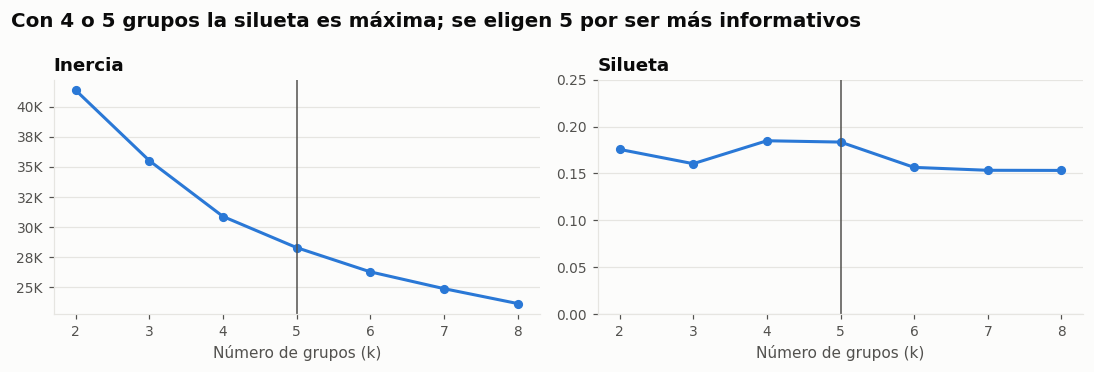

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(selection.index, selection["inercia"], color=BLUE, marker="o", markersize=5)
axes[0].set_title("Inercia")
axes[0].yaxis.set_major_formatter(COMPACT)
axes[1].plot(selection.index, selection["silueta"], color=BLUE, marker="o", markersize=5)
axes[1].set_title("Silueta")
axes[1].set_ylim(0, 0.25)
for ax in axes:
    ax.set_xlabel("Número de grupos (k)")
    ax.axvline(5, color=INK_SECONDARY, linewidth=1)
fig.suptitle("Con 4 o 5 grupos la silueta es máxima; se eligen 5 por ser más informativos",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_eleccion_k.png")
plt.show()

**Se eligen 5 grupos.** La silueta es prácticamente igual con 4 y con 5 y cae a partir de 6; la solución es estable y ningún grupo queda pequeño. Frente a 4, la solución de 5 separa un grupo adicional con sentido de negocio (los videos polémicos), como se ve en el perfilado.

**Advertencia:** la silueta es baja (cerca de 0,18). Los videos no forman islas separadas; forman un continuo, y los grupos son una forma útil de dividirlo, no categorías con fronteras nítidas. Un video cerca de una frontera podría caer en el grupo vecino.

In [5]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X)
centers = pd.DataFrame(kmeans.cluster_centers_, columns=features.columns)

# Nombre de cada grupo según el rasgo que más lo distingue (independiente del orden que asigne K-Means).
names = {}
remaining = list(centers.index)
for column, name in [
    ("Videos del canal", "Medios recurrentes"),
    ("Valoraciones negativas", "Polémicos"),
    ("Vistas", "Grandes éxitos"),
    ("Likes por vista", "Comunidad fiel"),
]:
    winner = centers.loc[remaining, column].idxmax()
    names[winner] = name
    remaining.remove(winner)
names[remaining[0]] = "Llegada lenta"

ORDER = ["Grandes éxitos", "Comunidad fiel", "Medios recurrentes", "Polémicos", "Llegada lenta"]
COLORS = dict(zip(ORDER, PALETTE))
data["segmento"] = pd.Categorical(pd.Series(kmeans.labels_, index=data.index).map(names), categories=ORDER)
centers.index = centers.index.map(names)
centers = centers.loc[ORDER]

data["segmento"].value_counts().reindex(ORDER).to_frame("videos").assign(
    porcentaje=lambda t: t["videos"] / t["videos"].sum() * 100
)

,videos,porcentaje
segmento,,
Grandes éxitos,1363,21.85
Comunidad fiel,2011,32.24
Medios recurrentes,1197,19.19
Polémicos,976,15.65
Llegada lenta,690,11.06


### 2.1 Validación con otro algoritmo

Si los grupos fueran un artefacto de K-Means, otro método daría una división muy distinta. Se compara con clustering jerárquico (Ward) sobre los mismos datos.

In [6]:
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
ari = adjusted_rand_score(kmeans.labels_, ward.labels_)
print(f"Coincidencia entre K-Means y clustering jerárquico (Rand ajustado): {ari:.2f}")
pd.crosstab(data["segmento"], pd.Series(ward.labels_, index=data.index, name="Grupo jerárquico"))

Coincidencia entre K-Means y clustering jerárquico (Rand ajustado): 0.45


Grupo jerárquico,0,1,2,3,4
segmento,,,,,
Grandes éxitos,195,154,966,48,0
Comunidad fiel,189,1678,110,34,0
Medios recurrentes,1023,81,7,86,0
Polémicos,222,127,49,578,0
Llegada lenta,18,116,82,311,163


La coincidencia es moderada (0,45), coherente con la silueta baja: al no haber fronteras nítidas, cada método corta el continuo en lugares algo distintos. Aun así, el núcleo de cuatro segmentos aparece con ambos métodos: el 85% de los Medios recurrentes, el 83% de Comunidad fiel, el 71% de los Grandes éxitos y el 59% de los Polémicos quedan juntos en un mismo grupo jerárquico. El segmento menos firme es Llegada lenta, que el método jerárquico reparte en dos.

## 3. Perfil de los segmentos

### 3.1 Qué distingue a cada uno

El mapa muestra el centro de cada segmento en unidades estandarizadas: 0 es el promedio de todos los videos, azul es por encima y rojo por debajo.

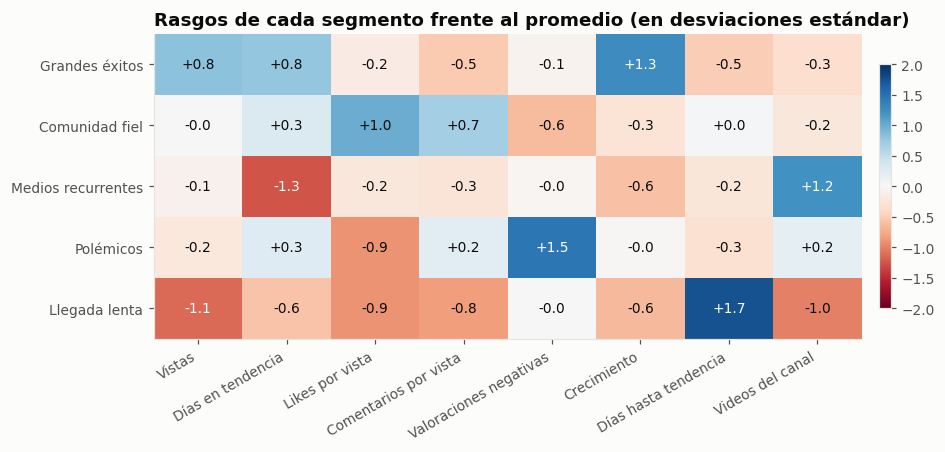

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.6))
image = ax.imshow(centers.values, cmap="RdBu", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(centers.columns)), centers.columns, rotation=30, ha="right")
ax.set_yticks(range(len(centers.index)), centers.index)
for i in range(centers.shape[0]):
    for j in range(centers.shape[1]):
        value = centers.iloc[i, j]
        ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=9,
                color="white" if abs(value) > 1.1 else "#0b0b0b")
ax.grid(False)
ax.set_title("Rasgos de cada segmento frente al promedio (en desviaciones estándar)")
fig.colorbar(image, ax=ax, shrink=0.8, pad=0.02)
fig.savefig(FIGURES_DIR / "04_perfil_segmentos.png")
plt.show()

In [8]:
profile = data.groupby("segmento", observed=True).agg(
    videos=("video_id", "count"),
    canales=("channel_title", "nunique"),
    vistas=("views_last", "median"),
    likes=("likes_last", "median"),
    dias_en_tendencia=("days_trending", "median"),
    likes_por_100_vistas=("like_rate", lambda s: s.median() * 100),
    pct_valoraciones_negativas=("dislike_share", lambda s: s.median() * 100),
    crecimiento=("views_growth", "median"),
    dias_hasta_tendencia=("days_to_trending", "median"),
    videos_del_canal=("channel_videos", "median"),
)
profile.style.format({
    "vistas": "{:,.0f}", "likes": "{:,.0f}", "dias_en_tendencia": "{:.0f}",
    "likes_por_100_vistas": "{:.1f}", "pct_valoraciones_negativas": "{:.1f}",
    "crecimiento": "{:.1f}×", "dias_hasta_tendencia": "{:.0f}", "videos_del_canal": "{:.0f}",
})

,videos,canales,vistas,likes,dias_en_tendencia,likes_por_100_vistas,pct_valoraciones_negativas,crecimiento,dias_hasta_tendencia,videos_del_canal
segmento,,,,,,,,,,
Grandes éxitos,1363,821,"1,695,390","34,320",8,2.3,3.6,3.9×,1,4
Comunidad fiel,2011,889,"438,733","20,927",6,4.8,1.8,1.5×,2,5
Medios recurrentes,1197,160,"529,609","9,496",2,2.0,3.7,1.2×,1,36
Polémicos,976,416,"348,814","3,071",6,1.0,16.4,1.7×,1,9
Llegada lenta,690,623,"58,327",477,3,0.9,4.0,1.1×,5,1


### 3.2 Relación con la categoría y el periodo

In [9]:
mix = pd.crosstab(data["category"], data["segmento"], normalize="columns") * 100
mix.columns = mix.columns.astype(str)
mix = mix[(pd.crosstab(data["category"], data["segmento"]).sum(axis=1) >= 100)]
overall = data["category"].value_counts(normalize=True) * 100
mix.insert(0, "Todos los videos", overall.reindex(mix.index))
mix.sort_values("Todos los videos", ascending=False).style.format("{:.0f}%").background_gradient(
    cmap="Blues", axis=None, vmin=0, vmax=40)

segmento,Todos los videos,Grandes éxitos,Comunidad fiel,Medios recurrentes,Polémicos,Llegada lenta
category,,,,,,
Entertainment,25%,23%,19%,37%,29%,23%
Music,13%,30%,13%,2%,3%,10%
Howto & Style,10%,6%,18%,8%,3%,6%
Comedy,9%,7%,11%,12%,5%,4%
People & Blogs,8%,5%,11%,6%,6%,10%
News & Politics,8%,3%,1%,8%,29%,6%
Sports,7%,4%,1%,17%,10%,7%
Science & Technology,6%,4%,7%,3%,5%,11%
Film & Animation,5%,8%,4%,2%,4%,9%


In [10]:
late = data.groupby("segmento", observed=True)["period"].apply(lambda s: (s == prep.PERIODS[1]).mean() * 100)
print(f"Videos del periodo marzo–junio en todo el dataset: {(data['period'] == prep.PERIODS[1]).mean():.0%}")
late.rename("% de videos de marzo–junio").to_frame().style.format("{:.0f}%")

Videos del periodo marzo–junio en todo el dataset: 30%


,% de videos de marzo–junio
segmento,
Grandes éxitos,31%
Comunidad fiel,30%
Medios recurrentes,44%
Polémicos,24%
Llegada lenta,18%


- **Los segmentos no son la categoría con otro nombre.** Entertainment aparece en todos. Pero hay afinidades claras: Música pesa el 30% de los Grandes éxitos (13% en general), Howto & Style el 18% de Comunidad fiel (10%), Sports el 17% de Medios recurrentes (7%) y News & Politics el 29% de los Polémicos (8%).
- **El ajuste por periodo funcionó en lo principal:** Grandes éxitos y Comunidad fiel tienen la misma proporción de videos de marzo–junio que el dataset (30%). Medios recurrentes tiene más (44%) y Llegada lenta menos (18%), coherente con que desde marzo es más difícil entrar a la lista para canales sin audiencia.

### 3.3 Ejemplos de cada segmento

Los cinco videos más cercanos al centro de cada segmento, es decir, los más representativos.

In [11]:
distances = kmeans.transform(X)[np.arange(len(X)), kmeans.labels_]
data["distancia_al_centro"] = distances
examples = (
    data.sort_values("distancia_al_centro")
    .groupby("segmento", observed=True)
    .head(5)
    .sort_values(["segmento", "distancia_al_centro"])
)
examples[["segmento", "title", "channel_title", "category", "views_last", "days_trending"]].style.format(
    {"views_last": "{:,.0f}"}).hide(axis="index")

segmento,title,channel_title,category,views_last,days_trending
Grandes éxitos,Star Wars Cast Takes Which Star Wars Character Are You? Quiz,BuzzFeed Celeb,Entertainment,"1,974,031",8
Grandes éxitos,Carrie Underwood - The Champion (Official Lyric Video) ft. Ludacris,carrieunderwoodVEVO,Music,"1,632,855",6
Grandes éxitos,Christopher Robin Official Teaser Trailer,Disney Movie Trailers,Film & Animation,"7,714,606",15
Grandes éxitos,Luke Combs - One Number Away,LukeCombsVEVO,Music,"996,503",6
Grandes éxitos,Eating BRUNCH at Taiwan 7-ELEVEN,Strictly Dumpling,Travel & Events,"2,093,619",9
Comunidad fiel,What's In My Travel Bag? | Zoella,Zoella,Howto & Style,"1,162,734",11
Comunidad fiel,First Time Cats Go Outside in New Catio,Cole and Marmalade,Pets & Animals,"392,184",6
Comunidad fiel,HORMONES | The Weekly #4 | LIFESTYLE,Sprinkleofglitter,Howto & Style,"539,045",5
Comunidad fiel,Trying The FRUITARIAN Raw Vegan Diet For A Week 🍎🍌🍍,Michelle Khare,Entertainment,"162,444",5
Comunidad fiel,Forging a Knife From a Wrench With Hydraulic Press | in 4K,Hydraulic Press Channel,Science & Technology,"394,975",5


### 3.4 Vista en dos dimensiones

Para ver los segmentos se proyectan las ocho variables en dos componentes principales. Es una simplificación: parte de la separación entre grupos ocurre en dimensiones que aquí no se ven.

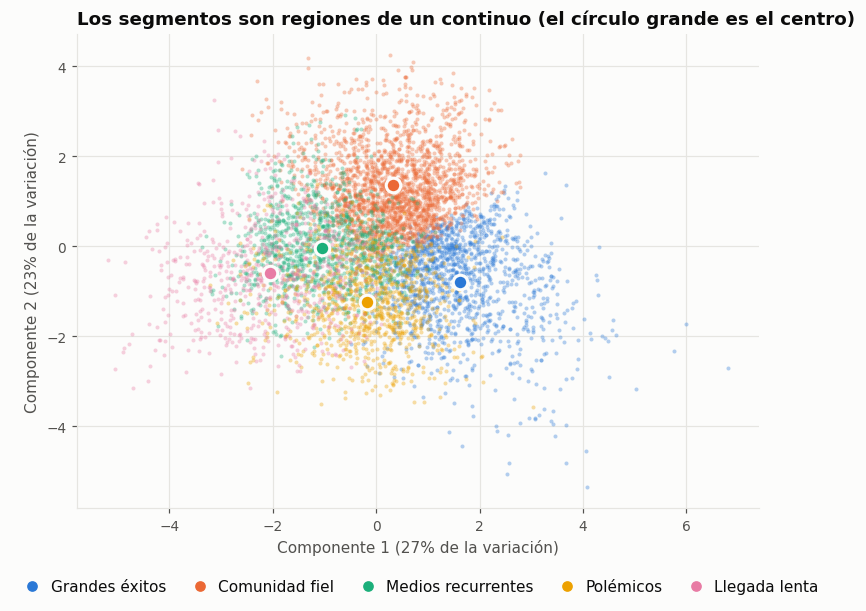

,Componente 1,Componente 2
Vistas,+0.47,-0.05
Días en tendencia,+0.51,-0.07
Likes por vista,+0.22,+0.67
Comentarios por vista,+0.06,+0.46
Valoraciones negativas,-0.09,-0.50
Crecimiento,+0.53,-0.28
Días hasta tendencia,-0.42,+0.05
Videos del canal,-0.08,-0.03


In [12]:
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X)
explained = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8, 5.6))
for name in ORDER:
    mask = (data["segmento"] == name).to_numpy()
    ax.scatter(coords[mask, 0], coords[mask, 1], s=7, alpha=0.35, color=COLORS[name], linewidths=0)
centers_2d = pca.transform(kmeans.cluster_centers_)
for cluster, name in names.items():
    ax.scatter(*centers_2d[cluster], s=90, color=COLORS[name], edgecolor="#fcfcfb", linewidth=2, zorder=3)
ax.set_xlabel(f"Componente 1 ({explained[0]:.0%} de la variación)")
ax.set_ylabel(f"Componente 2 ({explained[1]:.0%} de la variación)")
ax.set_title("Los segmentos son regiones de un continuo (el círculo grande es el centro)")
ax.grid(axis="x")
handles = [plt.Line2D([], [], marker="o", linestyle="", color=COLORS[n], label=n) for n in ORDER]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5,
          columnspacing=1.2, handletextpad=0.2)
fig.savefig(FIGURES_DIR / "04_segmentos_pca.png")
plt.show()

loadings = pd.DataFrame(pca.components_.T, index=features.columns, columns=["Componente 1", "Componente 2"])
loadings.style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-0.7, vmax=0.7)

## 4. Segmentos y canales: lectura para la decisión de sponsors

Un canal es un buen candidato a sponsor si sus videos caen de forma consistente en los segmentos deseables. Se revisan los canales con al menos 8 videos en tendencia.

In [13]:
channel_counts = data["channel_title"].value_counts()
frequent = data[data["channel_title"].isin(channel_counts[channel_counts >= 8].index)]
channel_mix = pd.crosstab(frequent["channel_title"], frequent["segmento"], normalize="index") * 100
channel_mix.columns = channel_mix.columns.astype(str)
channel_info = frequent.groupby("channel_title").agg(
    videos=("video_id", "count"),
    categoria=("category", lambda s: s.mode()[0]),
    vistas=("views_last", "median"),
    likes_por_100_vistas=("like_rate", lambda s: s.median() * 100),
)
channel_table = channel_info.join(channel_mix)
channel_table["segmento_principal"] = channel_mix.idxmax(axis=1)
print(f"Canales con 8 o más videos: {len(channel_table)}")
print(f"En promedio, el {channel_mix.max(axis=1).mean():.0f}% de los videos de un canal cae en un mismo segmento.")
channel_table["segmento_principal"].value_counts().reindex(ORDER).to_frame("canales")

Canales con 8 o más videos: 157
En promedio, el 65% de los videos de un canal cae en un mismo segmento.


,canales
segmento_principal,
Grandes éxitos,22
Comunidad fiel,57
Medios recurrentes,43
Polémicos,31
Llegada lenta,4


In [14]:
fmt = {"vistas": "{:,.0f}", "likes_por_100_vistas": "{:.1f}", **{s: "{:.0f}%" for s in ORDER}}
for segment in ["Grandes éxitos", "Comunidad fiel"]:
    top = (
        channel_table[channel_table["segmento_principal"] == segment]
        .sort_values([segment, "videos"], ascending=False)
        .head(10)[["videos", "categoria", "vistas", "likes_por_100_vistas", segment]]
    )
    display(top.style.format(fmt).set_caption(f"Canales cuyo segmento principal es «{segment}»"))

,videos,categoria,vistas,likes_por_100_vistas,Grandes éxitos
channel_title,,,,,
Sony Pictures Entertainment,10,Entertainment,"7,620,460",1.5,80%
Universal Pictures,14,Entertainment,"4,829,016",1.1,79%
Dude Perfect,12,Sports,"16,858,174",2.7,75%
Hannah Stocking,12,Comedy,"3,064,056",3.0,75%
Atlantic Records,8,Music,"1,078,972",3.9,75%
Simon's Cat,13,Pets & Animals,"460,046",3.9,62%
The Graham Norton Show,15,Entertainment,"1,467,369",1.2,60%
20th Century Fox,17,Film & Animation,"3,064,780",1.9,59%
Charlie Puth,9,Music,"3,976,296",4.5,56%


,videos,categoria,vistas,likes_por_100_vistas,Comunidad fiel
channel_title,,,,,
Simply Nailogical,12,Entertainment,"2,231,753",5.3,100%
William Osman,11,Science & Technology,"309,971",5.3,100%
vlogbrothers,11,People & Blogs,"238,661",5.7,100%
AnthonyPadilla,9,Comedy,"302,703",8.2,100%
Kurzgesagt – In a Nutshell,9,Education,"2,982,517",5.8,100%
Jackie Aina,8,Howto & Style,"543,962",8.1,100%
KathleenLights,8,Howto & Style,"531,128",5.0,100%
The Scran Line,8,Howto & Style,"51,160",5.3,100%
IISuperwomanII,18,Comedy,"1,595,913",7.4,94%


- **El segmento es en buena medida una propiedad del canal:** en promedio, el 65% de los videos de un canal cae en un mismo segmento. Eso permite clasificar canales, no solo videos.
- De los 157 canales con 8 o más videos, 57 son sobre todo de Comunidad fiel y 22 de Grandes éxitos. Son los dos grupos donde buscar sponsors.
- **Grandes éxitos** está dominado por estudios de cine, sellos musicales y creadores muy grandes (Dude Perfect, Universal, Sony): alcance alto, costo previsiblemente alto.
- **Comunidad fiel** reúne creadores independientes con entre 5 y 8 likes por cada 100 vistas, el doble o más que la mediana general (2,4), y varios con el 100% de sus videos en este segmento (Kurzgesagt, vlogbrothers, Simply Nailogical, Jackie Aina).

In [15]:
data[["video_id", "segmento"]].to_parquet(PROCESSED_DIR / "segments.parquet", index=False)
print("Segmentos guardados en data/processed/segments.parquet")

Segmentos guardados en data/processed/segments.parquet


## 5. Conclusiones

**Respuesta a la pregunta:** sí. Los videos en tendencia se pueden agrupar en cinco segmentos de comportamiento, estables y distintos de la categoría de YouTube.

| Segmento | Qué lo define | Lectura para la empresa |
|---|---|---|
| **Grandes éxitos** | Más vistas, más días en la lista y vistas que se multiplican mientras están en tendencia. Mucha música. | Es el objetivo de alcance. Difícil de lograr con un canal nuevo; se accede asociándose con quienes ya lo consiguen. |
| **Comunidad fiel** | Alcance medio pero la mayor interacción: más likes y comentarios por vista, y casi sin valoraciones negativas. Howto & Style, Comedy, People & Blogs. | El modelo más replicable para un canal de marca: audiencia que responde. Buen perfil de sponsor para generar tráfico al sitio. |
| **Medios recurrentes** | Canales que entran a tendencia casi a diario (programas de TV, deportes); cada video dura poco. | Presencia constante con contenido de actualidad. Requiere un volumen de producción que una marca no tiene. |
| **Polémicos** | Alta proporción de valoraciones negativas. Mucha noticia y política. | Alcance con riesgo reputacional. A evitar como sponsor y como estilo de contenido. |
| **Llegada lenta** | Pocas vistas, tardan varios días en llegar y duran poco; canales que aparecen una sola vez. | Es donde cae un canal sin audiencia previa. Es el punto de partida realista de un canal nuevo. |

**Limitaciones:**

- Los segmentos dividen un continuo; las fronteras no son nítidas (silueta de 0,18).
- Describen videos que **ya llegaron** a tendencia. No dicen qué separa a un video en tendencia de uno que no llegó.
- Usan métricas que solo se conocen después de publicar. Sirven para entender y para evaluar canales, no para predecir antes de publicar; de eso se ocupa el notebook 05.